# 01 · Follow One Whale

What would copying **every resolved bet** of a single smart-money wallet have
returned? We pull the wallet's resolved positions from OrcaLayer's `/backtest`
endpoint, order them by resolution time, and build a cumulative-P&L equity curve.

> ⚠️ **Informational only — NOT financial advice.** Past performance does not
> predict future results. These are historical, already-resolved markets.

> **Running in Google Colab?** Paste the snippet below into a new cell and run
> it first (installs dependencies, pulls the repo for the shared `utils/`
> helper, and prompts for your key), then continue from the next cell. Skip
> this if you cloned the repo and run locally.
>
> ```python
> !pip install -q orcalayer==0.2.0 pandas matplotlib httpx python-dotenv
> !git clone https://github.com/orcalayer/polymarket-backtest-cookbook.git
> %cd polymarket-backtest-cookbook/notebooks
> import os, getpass
> os.environ["ORCALAYER_API_KEY"] = getpass.getpass("OrcaLayer Premium API key: ")
> ```

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from utils.oc_backtest import backtest, positions_df, equity_curve, max_drawdown, win_rate

Pick a wallet. The default is a known smart whale; swap in any address from
the leaderboard (see notebook 02).

In [2]:
WALLET = "0x56687bf447db6ffa42ffe2204a05edaa20f55839"  # "Theo4"

Pull the resolved positions. This is the Premium `/backtest` endpoint, so it
needs `ORCALAYER_API_KEY` in your `.env`.

In [3]:
bt = backtest(WALLET, limit=500)
summary = bt["summary"]
summary

{'total': 28,
 'resolved': 28,
 'wins': 14,
 'losses': 14,
 'win_rate': 50.0,
 'total_pnl': 9919208.95}

Turn the resolved positions into a cumulative-P&L equity curve over time.

In [4]:
df = positions_df(bt)
curve = equity_curve(df)
curve["date"] = pd.to_datetime(curve["last_trade_ts"], unit="s")
curve.tail()

,last_trade_ts,pnl,equity,date
23,1730829933,13722.28,4542155.95,2024-11-05 18:05:33
24,1730830481,1173377.72,5715533.67,2024-11-05 18:14:41
25,1730840089,4203711.41,9919245.08,2024-11-05 20:54:49
26,1731476833,-0.17,9919244.91,2024-11-13 05:47:13
27,1731476951,-35.96,9919208.95,2024-11-13 05:49:11


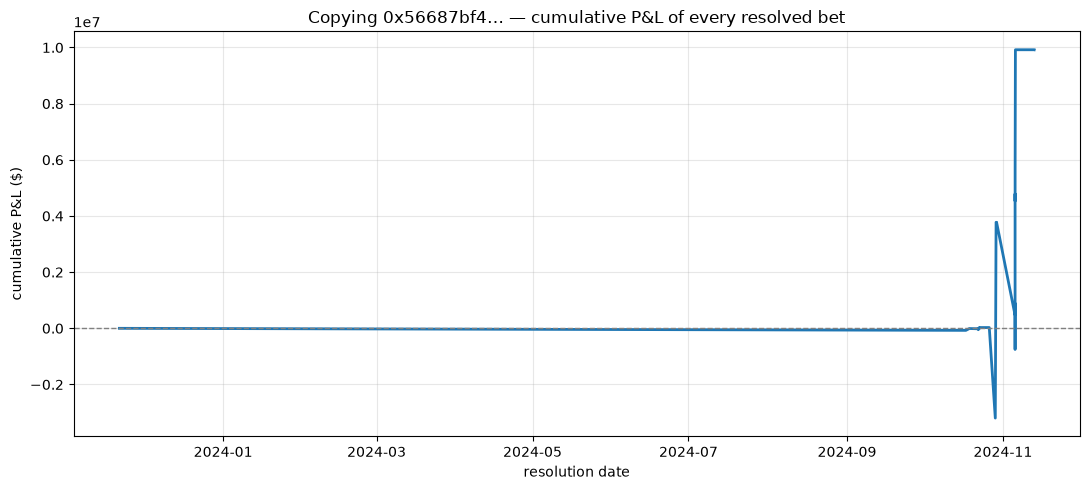

In [5]:
plt.figure(figsize=(11, 5))
plt.plot(curve["date"], curve["equity"], lw=2, color="#1f77b4")
plt.axhline(0, color="grey", lw=1, ls="--")
plt.title(f"Copying {WALLET[:10]}… — cumulative P&L of every resolved bet")
plt.xlabel("resolution date")
plt.ylabel("cumulative P&L ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Headline numbers.

In [6]:
final_pnl = float(curve["equity"].iloc[-1]) if not curve.empty else 0.0
print(f"Final P&L:        ${final_pnl:,.0f}")
print(f"Win rate:         {win_rate(df)}%")
print(f"Max drawdown:     ${max_drawdown(curve):,.0f}")
print(f"Resolved markets: {len(df)}")

Final P&L:        $9,919,209
Win rate:         50.0%
Max drawdown:     $-4,528,712
Resolved markets: 28


This is what *copying every resolved bet* of this wallet would have returned —
a backward-looking measurement, **not** a forward prediction. A high number
here can still come from a few lucky resolutions or a hedged structure; notebook
03 shows why the farmer filter matters before trusting any "top trader".

> ⚠️ Informational only — not financial advice.